# Ying's sparsifying preconditioner for the Lippmann–Schwinger equation

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Forgotten/jax-lippmann-schwinger/blob/main/notebooks/sparsifying_preconditioner_notebook.ipynb)

GMRES on the Lippmann–Schwinger equation needs more iterations as the frequency and the
contrast grow: unpreconditioned, a smooth contrast of 4 at $\omega = 80$ takes over a
thousand. This notebook demonstrates `jax_ls.sparsify`, an implementation of

> L. Ying, *Sparsifying preconditioner for the Lippmann–Schwinger equation*,
> Multiscale Model. Simul. **13**(2), 644–660 (2015); [arXiv:1408.4495](https://arxiv.org/abs/1408.4495)

which brings that to around ten, nearly independent of the frequency. It shows:

1. the idea: a 3×3 stencil that nearly annihilates the far field of $G$;
2. the sparse matrix that gets factorised;
3. residual histories with and without the preconditioner;
4. iteration counts as the frequency, the contrast and the grid change;
5. wall-clock time of the JAX solvers and of the near-field map;
6. how one factorisation is shared across a Gauss–Newton linearisation, and what a stale one costs.

In [1]:
# On Colab the package is not present, so install it from GitHub.
# Running from a local clone this cell does nothing.
import importlib
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("google.colab") is not None:
  subprocess.run(
    [
      sys.executable,
      "-m",
      "pip",
      "install",
      "-q",
      "--no-cache-dir",
      "--upgrade",
      "git+https://github.com/Forgotten/jax-lippmann-schwinger.git@main",
    ],
    check=True,
  )
  importlib.invalidate_caches()
  import jax_ls

  importlib.reload(jax_ls)
  if not hasattr(jax_ls, "with_sparsifying_preconditioner"):
    raise RuntimeError(
      "jax_ls installed but an older build is still loaded. "
      "Use Runtime > Restart session, then run this cell again."
    )

In [2]:
try:
  import context  # noqa: F401
except ImportError:
  pass

import time

import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sps
import scipy.sparse.linalg as spla

import jax
import jax.numpy as jnp

import jax_ls
from jax_ls import sparsify

jax.config.update("jax_enable_x64", True)


def gauss(c, width=10.0):
  """A smooth contrast."""
  return lambda X, Y: c * jnp.exp(-width * (X**2 + Y**2))


def disc(c, radius=0.3):
  """A discontinuous contrast."""
  return lambda X, Y: c * (X**2 + Y**2 < radius**2) * 1.0

## 1. The idea

`jax_ls` solves for the induced source $\sigma$

$$A\sigma = f, \qquad A = -I + \omega^2 D_\nu G, \qquad D_\nu = \operatorname{diag}(\nu),$$

with $G$ the volume potential, applied by FFT. $G$ is dense, but it is the Green's
function of a *local* operator, so a small local stencil applied to it nearly cancels its
far field. For every grid point $p$, Ying picks weights $\alpha_p$ on the 3×3 neighbourhood
of $p$ such that

$$(\mathcal{A} G)_{pj} = \sum_{k} \alpha_{p,k}\, G_{p+o_k,\,j} \approx 0 \qquad \text{for } j \text{ outside the stencil},$$

taking $\alpha_p$ from the smallest left singular vector of those rows of $G$, restricted to
the far columns. What survives is a 9-point matrix $C \approx \mathcal{A} G$.

Ying works with the *field* form $-I + \omega^2 G D_\nu$. Here that is $A^T$, because the
discrete $G$ is complex-symmetric. So

$$\mathcal{A} A^T \approx -\mathcal{A} + \omega^2 C D_\nu =: M \quad\Longrightarrow\quad A^{-1} \approx P := \mathcal{A}^T M^{-T}.$$

$M$ is sparse with the 9-point pattern. One LU of it, solved transposed, gives a
preconditioner, applied on the right: GMRES solves $A P y = f$ and returns $\sigma = P y$.

$G$ is a convolution, so a stencil depends only on which neighbours exist. That leaves
nine types (interior, four edges, four corners), each computed once.

In [3]:
n, omega = 127, 80.0
params = jax_ls.init_params(1.0, 1.0, n, n, omega, sparsify=True)
plain = params.replace(sparsifier=None)
stencils = params.sparsifier

print(
  f"grid {n}x{n}, omega = {omega}, {2 * np.pi * n / omega:.1f} points per wavelength"
)
print("s_min / s_max of the far-field block, per stencil type:")
print(np.asarray(stencils.quality).reshape(3, 3).round(4))

interior = np.asarray(stencils.alpha)[:, n // 2, n // 2].reshape(3, 3)
print("\ninterior stencil, normalised by its centre:")
print((interior / interior[1, 1]).round(4))

grid 127x127, omega = 80.0, 10.0 points per wavelength
s_min / s_max of the far-field block, per stencil type:
[[0.0075 0.0043 0.0075]
 [0.0043 0.0008 0.0043]
 [0.0075 0.0043 0.0075]]

interior stencil, normalised by its centre:
[[-0.1  +0.0003j -0.187-0.0003j -0.1  +0.0003j]
 [-0.187-0.0003j  1.   -0.j     -0.187-0.0003j]
 [-0.1  +0.0003j -0.187-0.0003j -0.1  +0.0003j]]


The interior stencil is close to a discrete Helmholtz operator: a centre weight and
symmetric neighbours. The plot shows one row of $G$ and of $\mathcal{A} G$ around an
interior point. $\mathcal{A}$ does not make the far field vanish; it lowers it by orders of
magnitude relative to the near field. That residue is why GMRES still needs a few
iterations.

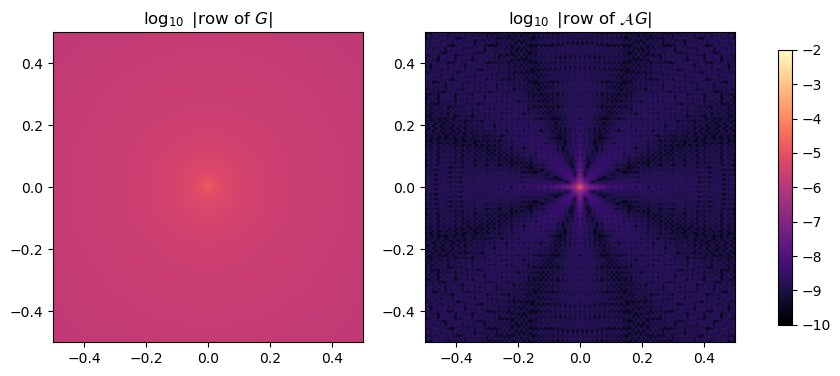

G       far / near magnitude: 4.7e-01
Acal G  far / near magnitude: 1.5e-02


In [4]:
p = (n // 2) * n + n // 2
e_p = jnp.zeros(params.n_dof, dtype=complex).at[p].set(1.0)
g_row = np.asarray(
  params.kernel.apply(e_p)
)  # a column of G = a row, G being symmetric
# Row p of (Acal G) is (Acal G)^T e_p = G Acal^T e_p.
ag_row = np.asarray(
  params.kernel.apply(
    sparsify.apply_stencil_transpose(stencils.domain, stencils.alpha, e_p)
  )
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, row, title in zip(
  axes, (g_row, ag_row), ("row of $G$", r"row of $\mathcal{A}G$")
):
  im = ax.imshow(
    np.log10(np.abs(row).reshape(n, n) + 1e-16),
    vmin=-10,
    vmax=-2,
    cmap="magma",
    extent=[-0.5, 0.5, -0.5, 0.5],
    origin="lower",
  )
  ax.set_title(f"$\\log_{{10}}$ |{title}|")
fig.colorbar(im, ax=axes, shrink=0.85)
plt.show()

far = np.ones((n, n), bool)
far[n // 2 - 1 : n // 2 + 2, n // 2 - 1 : n // 2 + 2] = False
far = far.ravel()
for name, row in (("G", g_row), ("Acal G", ag_row)):
  print(
    f"{name:7s} far / near magnitude: {np.abs(row[far]).max() / np.abs(row[~far]).max():.1e}"
  )

## 2. The sparse matrix

$M$ has the 9-point pattern and changes with $\nu$. It is factorised on the host with
SuperLU, in a geometric nested-dissection order (`sparsify.nested_dissection`): the
ordering Ying's $O(N^{1.5})$ cost estimate assumes. At $n = 255$ that factorises in about
0.5 s. COLAMD took 1.5–5 s and `MMD_AT_PLUS_A` 59 s.

N = 16129, nnz(M) = 143641 (8.9 per row)
LU in 0.15 s, fill nnz(L + U) = 1.23e+06 (76 per row)


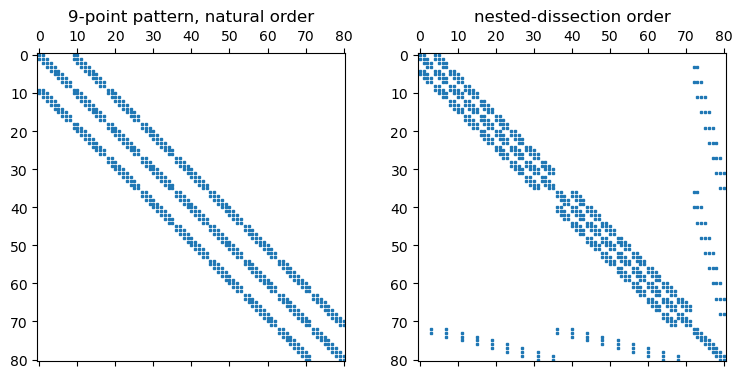

In [5]:
A_cal, C = stencils.matrices()
nu = np.asarray(params.domain.sample(disc(2.0)))
M = (-A_cal + omega**2 * C @ sps.diags(nu)).tocsr()

t0 = time.perf_counter()
lu = sparsify._PermutedLU(M, sparsify.nested_dissection(n, n))
t_lu = time.perf_counter() - t0
print(
  f"N = {params.n_dof}, nnz(M) = {M.nnz} ({M.nnz / params.n_dof:.1f} per row)"
)
print(
  f"LU in {t_lu:.2f} s, fill nnz(L + U) = {lu.lu.L.nnz + lu.lu.U.nnz:.2e} ({(lu.lu.L.nnz + lu.lu.U.nnz) / params.n_dof:.0f} per row)"
)

small = 9
perm = sparsify.nested_dissection(small, small)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
A_small = sps.csr_matrix(
  sparsify._assemble(
    jax_ls.Domain(1.0, 1.0, small, small), np.ones((9, small, small))
  )
)
axes[0].spy(A_small, markersize=2)
axes[0].set_title("9-point pattern, natural order")
axes[1].spy(A_small[perm][:, perm], markersize=2)
axes[1].set_title("nested-dissection order")
plt.show()

## 3. Residual histories

The forward operator at $\omega = 80$ on a disc of contrast 2, which has a jump. Iterations
are counted with SciPy's GMRES driving the jitted `jax_ls` operator and preconditioner,
without restarts. The JAX solver runs in a compiled loop and does not report a count.

plain:       300 iterations, true residual 2.8e-02
sparsified:   14 iterations, true residual 6.8e-07


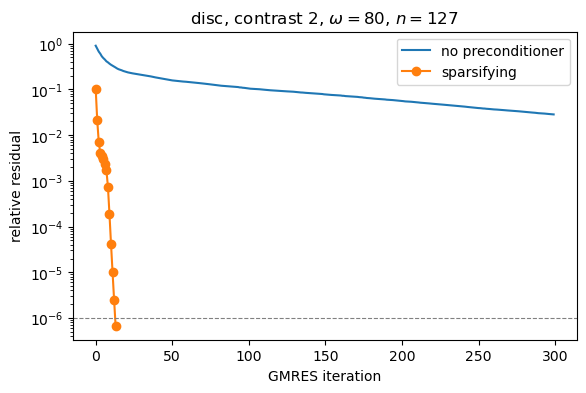

In [6]:
def residual_history(params, nu, precondition=True, budget=400, nu_factor=None):
  """Relative residual after each GMRES iteration, and the true final one."""
  apply_A = jax.jit(lambda v: jax_ls.apply_lipp_schwin(params, nu, v))
  P = (
    jax.jit(
      jax_ls.preconditioner_for(params, nu if nu_factor is None else nu_factor)
    )
    if precondition
    else None
  )

  def matvec(y):
    y = jnp.asarray(y)
    return np.array(apply_A(P(y) if P is not None else y))

  b = np.random.default_rng(0).standard_normal(params.n_dof) + 0j
  history = []
  y, _ = spla.gmres(
    spla.LinearOperator((params.n_dof,) * 2, matvec=matvec, dtype=complex),
    b,
    rtol=1e-6,
    restart=budget,
    maxiter=1,
    callback=history.append,
    callback_type="pr_norm",
  )
  x = jnp.asarray(y) if P is None else P(jnp.asarray(y))
  true = np.linalg.norm(np.asarray(apply_A(x)) - b) / np.linalg.norm(b)
  return np.asarray(history), true


nu_disc = params.domain.sample(disc(2.0))
h_plain, r_plain = residual_history(
  params, nu_disc, precondition=False, budget=300
)
h_sparse, r_sparse = residual_history(params, nu_disc)
print(f"plain:      {len(h_plain):4d} iterations, true residual {r_plain:.1e}")
print(
  f"sparsified: {len(h_sparse):4d} iterations, true residual {r_sparse:.1e}"
)

plt.figure(figsize=(6.5, 4))
plt.semilogy(h_plain, label="no preconditioner")
plt.semilogy(h_sparse, "o-", label="sparsifying")
plt.axhline(1e-6, color="gray", lw=0.8, ls="--")
plt.xlabel("GMRES iteration")
plt.ylabel("relative residual")
plt.title(r"disc, contrast 2, $\omega = 80$, $n = 127$")
plt.legend()
plt.show()

## 4. Iteration counts

### Frequency
The grid is kept at about ten points per wavelength, so $n$ doubles with $\omega$.
Unpreconditioned GMRES gets a budget of 300 iterations.

In [7]:
freq_rows = []
for omega_k, n_k in ((20.0, 63), (40.0, 63), (80.0, 127), (160.0, 255)):
  p_k = jax_ls.init_params(1.0, 1.0, n_k, n_k, omega_k, sparsify=True)
  nu_k = p_k.domain.sample(gauss(2.0))
  t0 = time.perf_counter()
  its_s = len(residual_history(p_k, nu_k)[0])
  t_s = time.perf_counter() - t0
  its_p = len(residual_history(p_k, nu_k, precondition=False, budget=300)[0])
  freq_rows.append((omega_k, n_k, its_p, its_s))
  print(
    f"omega = {omega_k:5.0f}  n = {n_k:3d}   plain {its_p if its_p < 300 else '>300':>5}   sparsified {its_s:3d}   ({t_s:.1f} s incl. stencils + LU)"
  )

omega =    20  n =  63   plain    34   sparsified   6   (0.1 s incl. stencils + LU)


omega =    40  n =  63   plain    96   sparsified   7   (0.2 s incl. stencils + LU)


omega =    80  n = 127   plain   297   sparsified   8   (0.8 s incl. stencils + LU)


omega =   160  n = 255   plain  >300   sparsified  11   (1.8 s incl. stencils + LU)


### Contrast
At $\omega = 40$, $n = 127$, for a smooth Gaussian and for a disc with a jump. Ying's
analysis assumes a smooth medium. A jump costs about twice as many iterations but stays
far below the unpreconditioned count.

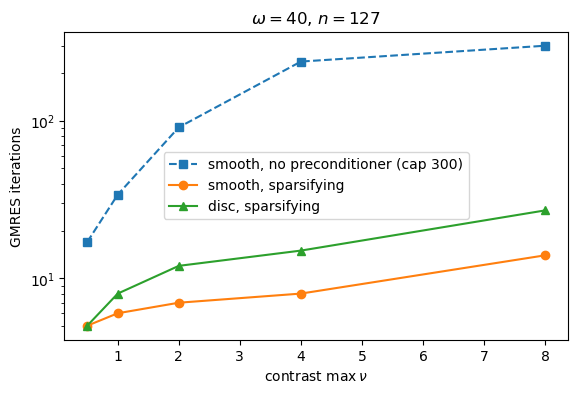

smooth: [5, 6, 7, 8, 14]  disc: [5, 8, 12, 15, 27]  plain smooth: [17, 34, 91, 238, 300]


In [8]:
p40 = jax_ls.init_params(1.0, 1.0, 127, 127, 40.0, sparsify=True)
contrasts = (0.5, 1.0, 2.0, 4.0, 8.0)
counts = {"gauss": [], "disc": []}
for c in contrasts:
  for name, profile in (("gauss", gauss), ("disc", disc)):
    counts[name].append(
      len(residual_history(p40, p40.domain.sample(profile(c)))[0])
    )
plain_gauss = [
  len(
    residual_history(
      p40, p40.domain.sample(gauss(c)), precondition=False, budget=300
    )[0]
  )
  for c in contrasts
]

plt.figure(figsize=(6.5, 4))
plt.semilogy(
  contrasts, plain_gauss, "s--", label="smooth, no preconditioner (cap 300)"
)
plt.semilogy(contrasts, counts["gauss"], "o-", label="smooth, sparsifying")
plt.semilogy(contrasts, counts["disc"], "^-", label="disc, sparsifying")
plt.xlabel(r"contrast $\max\,\nu$")
plt.ylabel("GMRES iterations")
plt.title(r"$\omega = 40$, $n = 127$")
plt.legend()
plt.show()
print(
  "smooth:",
  counts["gauss"],
  " disc:",
  counts["disc"],
  " plain smooth:",
  plain_gauss,
)

### A contrast that reaches the boundary
Ying assumes $\nu = 0$ in a buffer next to the boundary. Here it is nonzero everywhere, so
the edge and corner stencils matter. Matching them is exactly what the Julia reference
implementation appears to get wrong (its $\mathcal{A}$ and $C$ entries are ordered
differently on four edges and two corners). `tests/test_sparsify.py` checks
$C = \mathcal{A}G$ at every point, boundary included.

In [9]:
nu_edge = p40.domain.sample(
  lambda X, Y: 1.0 + 0.5 * jnp.cos(3 * X) * jnp.cos(2 * Y)
)
print(
  "plain     ",
  len(residual_history(p40, nu_edge, precondition=False, budget=300)[0]),
)
print("sparsified", len(residual_history(p40, nu_edge)[0]))

plain      300


sparsified 18


## 5. Wall-clock time with the JAX solvers

Attaching the stencils to the parameters is all it takes. `ls_solver`, the near-field map,
its derivatives and the inversions all pick the preconditioner up from `params`. The
timings below are after compilation and include the factorisation, which happens on first
use of a contrast.

In [10]:
def timed(fn, *args, repeat=1):
  jax.block_until_ready(fn(*args))  # compile
  best = np.inf
  for _ in range(repeat):
    sparsify.clear_factorizations()  # charge the factorisation every time
    t0 = time.perf_counter()
    out = jax.block_until_ready(fn(*args))
    best = min(best, time.perf_counter() - t0)
  return out, best


f = jnp.asarray(np.random.default_rng(1).standard_normal(params.n_dof) + 0j)
config = jax_ls.GmresConfig(tol=1e-6, restart=20, maxiter=200)
for label, nu_k in (
  ("smooth c=2", params.domain.sample(gauss(2.0))),
  ("disc c=2", nu_disc),
):
  (_, info_p), t_p = timed(
    lambda nu: jax_ls.ls_solver_with_info(plain, nu, f, config), nu_k
  )
  (_, info_s), t_s = timed(
    lambda nu: jax_ls.ls_solver_with_info(params, nu, f, config), nu_k
  )
  print(
    f"{label:11s} plain {t_p:6.2f} s ({info_p})   sparsified {t_s:5.2f} s ({info_s})   x{t_p / t_s:.0f}"
  )

smooth c=2  plain   5.12 s (converged (relative residual 5.80e-07))   sparsified  0.67 s (converged (relative residual 9.84e-14))   x8


disc c=2    plain  42.35 s (NOT CONVERGED (relative residual 1.89e-02))   sparsified  0.55 s (converged (relative residual 1.76e-10))   x78


The near-field map solves one system per source. All sources go through the host LU as a
single block right-hand side, and they share one factorisation.

In [11]:
nf_plain = jax_ls.init_params_near_field(1.0, 1.0, 127, 127, 1.0, 32, 80.0)
nf_sparse = nf_plain.replace(
  ls_params=jax_ls.with_sparsifying_preconditioner(nf_plain.ls_params)
)
nu_nf = nf_plain.ls_params.domain.sample(gauss(2.0))

d_plain, t_plain = timed(jax_ls.near_field_map, nf_plain, nu_nf)
d_sparse, t_sparse = timed(jax_ls.near_field_map, nf_sparse, nu_nf)
print(
  f"32 sources: plain {t_plain:.2f} s, sparsified {t_sparse:.2f} s (x{t_plain / t_sparse:.1f})"
)
print(
  f"relative difference of the data: {float(jnp.linalg.norm(d_sparse - d_plain) / jnp.linalg.norm(d_plain)):.1e}"
)
print("factorisations:", sparsify.factorization_stats())

32 sources: plain 321.92 s, sparsified 10.54 s (x30.5)
relative difference of the data: 7.7e-05
factorisations: {'factorizations': 1, 'hits': 22}


## 6. In an inversion

$M$ depends on $\nu$, so the factorisation has to follow the contrast. A Gauss–Newton step
fixes $\nu$ and then applies $J$ and $J^H$ many times. Every one of those solves, forward
and adjoint, for every source, shares one LU. The adjoint operator
$-I + \omega^2 D_\nu G^H$ is $\overline{A(\bar\nu)}$, so for a real contrast it uses the
same factorisation.

In [12]:
sparsify.clear_factorizations()
lin = jax_ls.linearize(nf_sparse, nu_nf)
t = nf_sparse.ls_params.domain.sample(gauss(1.0, width=40.0))
t0 = time.perf_counter()
for _ in range(5):
  jax.block_until_ready(lin.vjp(lin.jvp(t)))
print(f"5 x (J, J^H) about one contrast: {time.perf_counter() - t0:.2f} s")
print("factorisations:", sparsify.factorization_stats())

5 x (J, J^H) about one contrast: 96.39 s
factorisations: {'factorizations': 1, 'hits': 252}


Between outer steps the contrast changes, and so does the best factorisation. A stale one
still works, since GMRES is exact either way, but it costs iterations. `refactor_rtol`
reuses a cached factorisation for any contrast within that relative distance. The counts
below are for a factorisation built from a wrong contrast:

In [13]:
nu_true = p40.domain.sample(gauss(2.0))
for label, nu0 in (
  ("exact", nu_true),
  ("0.95 nu", 0.95 * nu_true),
  ("0.9 nu", 0.9 * nu_true),
  ("0.7 nu", 0.7 * nu_true),
  ("0.5 nu", 0.5 * nu_true),
):
  its = len(residual_history(p40, nu_true, nu_factor=nu0)[0])
  print(f"LU built from {label:8s}: {its:3d} iterations")

LU built from exact   :   7 iterations


LU built from 0.95 nu :   6 iterations


LU built from 0.9 nu  :   9 iterations


LU built from 0.7 nu  :  20 iterations


LU built from 0.5 nu  :  36 iterations


## Takeaways

* Iteration counts stay roughly flat as $\omega$ and the grid grow together, and grow only
  slowly with the contrast. Unpreconditioned GMRES grows with both.
* Discontinuous media cost about twice as many iterations as smooth ones, consistent with
  the smoothness assumption in Ying's analysis.
* The setup has two parts:
  * the stencils, about 81 kernel applications and nine small SVDs per frequency;
  * one sparse LU per contrast, shared by every solve at that contrast, forward and adjoint.
* The LU runs on the CPU through `jax.pure_callback`. On an accelerator each iteration then
  pays a host round trip. Replacing the LU with sweeping (Liu and Ying,
  [arXiv:1705.09443](https://arxiv.org/abs/1705.09443)) or polarized traces (Zepeda-Núñez
  and Zhao, SISC 38(5), 2016) would keep everything on the device.